# Fixed Income Risk Dashboard
### Task 05 · Alert Policy Review & Optimization

**RiskHub Python Lab | Incident Simulation | Detection Coverage | False-Alert Control | Policy Sign-off**

> **Business question:** Which alert policy detects enough trading-book and market-data incidents **while they are still live**, without overwhelming the desk with false alerts?

---

### Decision snapshot

| Evaluation | Result |
|:--|:--|
| Recommended policy | **`SCALED+FEED+LATE`** |
| Synthetic incident trials | **1,200** across six incident types |
| Overall detection while live | **93.8%** |
| Minimum detection for any incident type | **87.0%** |
| False alerts on clean 2023 / 2024 days | **1 / 0** |
| Model selection | Meets all defined constraints |

This notebook tests five transparent alert policies using a seeded, synthetic incident-injection experiment. It separates **clean-world calibration**, **prospective signal construction**, and **retrospective outcome scoring**. It then exports an auditable snapshot for an interactive C# / Excel dashboard.

**Scope:** Simulated portfolio and historical data. The sign-off is an *exercise policy selection*, not an authorization to use the method in production.


## 01 · Decision framework and experiment design

The starting point is a control problem, not a charting exercise. A desk needs a monitoring policy that balances three outcomes:

| Outcome | Question it answers |
|:--|:--|
| **Coverage** | Does at least one selected signal fire while an incident is active? |
| **False-alert burden** | How many clean mornings would require an unnecessary review? |
| **Timeliness** | On which morning after the first detectable day does the first alert arrive? |

Five candidate policies will be evaluated on the **same 1,200 injected incidents** (200 per kind), using fixed random seed `2024`. The decision criteria are specified in code **before** results are inspected; the selected policy is the first eligible candidate ranked by false-alert burden, then detection delay.

The simulation is designed for *comparative testing* and does not provide a statistically independent out-of-sample validation.


## 02 · Market data, bond book and reporting calendar

The input feed contains daily continuously compounded zero rates at **11 curve vertices (3M–30Y)** and the reported desk P&L. Nineteen fixed-rate government bonds and an amended trade blotter define the model portfolio.

- Yield curves are expressed in percent; daily yield changes are converted to basis points (bp).
- Position amounts in the blotter are millions of face value.
- Reports are evaluated for **2023 and 2024**; incident injection is restricted to 2024.
- Each of the 2023 and 2024 clean reporting periods is also evaluated independently for false alarms.

The project-root lookup is relative to the notebook location, so this file can live in `Task5_Review_Policy/` without hardcoding a Windows username.


In [1]:
import os
from pathlib import Path

# Resolve DataSource when the notebook is in a Task5 subfolder.
if os.environ.get("RAD_RISK_ROOT"):
    PROJECT_ROOT = Path(os.environ["RAD_RISK_ROOT"]).expanduser().resolve()
else:
    current = Path.cwd().resolve()
    PROJECT_ROOT = next(
        (p for p in (current, *current.parents)
         if (p / "DataSource" / "rates_desk_feed.csv").is_file()),
        None
    )
    if PROJECT_ROOT is None:
        raise FileNotFoundError(
            "DataSource/rates_desk_feed.csv not found. Set RAD_RISK_ROOT."
        )

DATA_FILE = PROJECT_ROOT / "DataSource" / "rates_desk_feed.csv"
print("Project root:", PROJECT_ROOT)
print("Data file:", DATA_FILE)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# == Setup (done for you) ==
df = pd.read_csv(
    DATA_FILE,
    parse_dates=['date'],
    index_col='date'
)
DATES = df.index                                   # business days 2020-12-31 .. 2024-12-31
LAB = [c[2:] for c in df.columns if c.startswith('Z_')]          # '3M', '6M', ..., '30Y'
TEN = np.array([0.25, 0.5, 1, 2, 3, 5, 7, 10, 15, 20, 30])       # years of the Z_ columns: the curve's VERTICES
Z = df[['Z_' + x for x in LAB]].to_numpy()         # the curve FEED as received: zero yields, %, continuously compounded
PNL = df['PNL_REPORTED'].to_numpy()                # the P&L system's daily desk P&L, USD (NaN before 2023-01-03)
REP = np.where(DATES >= '2023-01-03')[0]           # report mornings: every day with a reported P&L
BONDS = {   # bond: (coupon % a year, paid twice a year, maturity date)
    'GOV_23': (0.875, '2023-09-30'), 'GOV_24': (1.500, '2024-05-15'), 'GOV_25': (2.750, '2025-08-15'),
    'GOV_26': (4.125, '2026-06-15'), 'GOV_27': (3.250, '2027-11-15'), 'GOV_27B': (4.500, '2027-05-15'),
    'GOV_28': (4.000, '2028-05-15'), 'GOV_29': (3.750, '2029-02-15'), 'GOV_29B': (4.000, '2029-08-15'),
    'GOV_30': (4.000, '2030-02-15'), 'GOV_31': (4.125, '2031-08-15'), 'GOV_32': (2.875, '2032-05-15'),
    'GOV_33': (3.500, '2033-02-15'), 'GOV_34': (4.250, '2034-02-15'), 'GOV_37': (4.000, '2037-11-15'),
    'GOV_42': (3.250, '2042-08-15'), 'GOV_44': (4.375, '2044-02-15'), 'GOV_52': (3.000, '2052-08-15'),
    'GOV_53': (4.125, '2053-08-15'),
}
IDS = list(BONDS)
BLOTTER = [   # the risk system's trade blotter: (ticket, booked, traded, bond, face USD m: + bought / - sold)
    ('T001', '2022-12-30', '2022-12-30', 'GOV_23', 70), ('T002', '2022-12-30', '2022-12-30', 'GOV_24', 60),
    ('T003', '2022-12-30', '2022-12-30', 'GOV_25', 80), ('T004', '2022-12-30', '2022-12-30', 'GOV_27', 150),
    ('T005', '2022-12-30', '2022-12-30', 'GOV_29', 90), ('T006', '2022-12-30', '2022-12-30', 'GOV_32', -120),
    ('T007', '2022-12-30', '2022-12-30', 'GOV_33', -60), ('T008', '2022-12-30', '2022-12-30', 'GOV_37', 40),
    ('T009', '2022-12-30', '2022-12-30', 'GOV_42', -50), ('T010', '2022-12-30', '2022-12-30', 'GOV_52', 35),
    ('T011', '2023-02-14', '2023-02-14', 'GOV_26', 50), ('T012', '2023-04-20', '2023-04-20', 'GOV_32', 40),
    ('T013', '2023-06-07', '2023-06-07', 'GOV_30', 70), ('T014', '2023-08-23', '2023-08-23', 'GOV_44', -30),
    ('T015', '2023-10-11', '2023-10-11', 'GOV_27', -50), ('T016', '2023-11-29', '2023-11-29', 'GOV_53', 25),
    ('T017', '2024-01-17', '2024-01-17', 'GOV_25', -40), ('T018', '2024-02-21', '2024-02-21', 'GOV_30', 30),
    ('T019', '2024-04-10', '2024-04-10', 'GOV_34', 50), ('T019', '2024-04-16', '2024-04-10', 'GOV_34', -50),
    ('T020', '2024-05-22', '2024-05-22', 'GOV_42', 20),
    ('T021', '2024-06-12', '2024-06-12', 'GOV_27B', 40), ('T021', '2024-06-26', '2024-06-12', 'GOV_27B', 4),
    ('T022', '2024-08-07', '2024-08-07', 'GOV_44', 15),
    ('T026', '2024-08-21', '2024-08-21', 'GOV_28', 260), ('T027', '2024-08-21', '2024-08-21', 'GOV_31', -170),
    ('T023', '2024-09-12', '2024-09-09', 'GOV_29B', 8),
    ('T025', '2024-12-04', '2024-12-04', 'GOV_26', -20),
]   # a ticket that appears twice was AMENDED: its later row replaces the earlier one from that booked date
VAR_DAYS, VAR_K = 500, 5    # 1-day 99% HS VaR: the 5th worst of the last 500 daily curve moves (1% of 500)


Project root: /mnt/data
Data file: /mnt/data/DataSource/rates_desk_feed.csv


## 03 · Shared valuation and risk-exposure engine

The lab's bond-pricing engine is reused to build a consistent market-risk baseline for both clean-world calibration and synthetic error injection. These helpers are not new policy rules; they provide prices, position histories and per-vertex DV01.

**Valuation:** The present value of each bond is calculated by discounting the remaining coupon and principal cash flows with linearly interpolated zero rates.

$$
PV_b(t) = \sum_{i\in\mathrm{future\ flows}} CF_{b,i}\,\exp\!\left(-\frac{z(\tau_i)}{100}\tau_i\right)
$$

The resulting Key-Rate DV01 ladder measures how much the modeled portfolio value changes for a one-basis-point decline at each curve vertex.


In [2]:
def cash_flows(bond):
    """Done for you: the bond's payment dates after the data starts (every 6 months back from maturity, unadjusted)
    and its payments per 100 face: coupon / 2 on each date, + 100 at maturity."""
    cpn, mat = BONDS[bond]
    mat = pd.Timestamp(mat)
    dates = pd.DatetimeIndex([mat - pd.DateOffset(months=6 * k) for k in range(80)][::-1])
    dates = dates[dates > DATES[0]]
    cf = np.full(len(dates), cpn / 2)
    cf[-1] += 100.0
    return dates, cf


def interp_weights(tau):
    """Done for you: weights W (shape tau.shape + (11,)) with W @ curve = the zero rate at each tau, linear between
    vertices and flat beyond the first and last. Each row has at most two non-zero weights, summing to 1."""
    tc = np.clip(tau, TEN[0], TEN[-1])
    j = np.clip(np.searchsorted(TEN, tc, side='right') - 1, 0, len(TEN) - 2)
    a = (tc - TEN[j]) / (TEN[j + 1] - TEN[j])
    W = np.zeros(np.shape(tau) + (len(TEN),))
    np.put_along_axis(W, j[..., None], (1 - a)[..., None], axis=-1)
    W2 = np.zeros_like(W)
    np.put_along_axis(W2, (j + 1)[..., None], a[..., None], axis=-1)
    return W + W2


### 03.1 Position reconstruction and historical risk arrays

Each ticket's later amendment supersedes its earlier booking **from the amendment's booking date** in the received book. The corrected book defined later instead uses retrospectively established trade dates. This timing distinction is important for interpreting the testing environment.

`history()` produces bond-level present values, aged values, cash payments and DV01 ladders across all reporting days. The constant `UNIT = 1e4` converts USD millions of face multiplied by price-per-100 units into USD.


In [3]:
def positions_history(blotter=BLOTTER):
    """Done for you (Task 1's book_on, for every day at once): the position in each bond (days x bonds, USD m
    face) at each close. Each blotter row changes its ticket's face from that row's booked date onwards."""
    b = pd.DataFrame(blotter, columns=['ticket', 'booked', 'traded', 'bond', 'face'])
    step = b['face'] - b.groupby('ticket')['face'].shift(1).fillna(0)
    Q = np.zeros((len(DATES), len(IDS)))
    for r, bond, s in zip(DATES.searchsorted(pd.to_datetime(b['booked'])), b['bond'], step):
        Q[r:, IDS.index(bond)] += s
    return Q


def history(curves):
    """Done for you (Task 1's price_and_ladder, for every day and bond at once). Per 100 face, rows = days, columns =
    bonds: V = value off curve t on day t; VA = value off curve t-1 on day t (the bond one day OLDER, on YESTERDAY's
    curve); K, KA = the key-rate ladders of the same two (days x bonds x 11); CASH = what the bond paid in (t-1, t]."""
    prev = np.vstack([curves[:1], curves[:-1]])
    out = {k: [] for k in ('V', 'VA', 'K', 'KA', 'CASH')}
    for bond in IDS:
        dates, cf = cash_flows(bond)
        tau = (dates.values[None, :] - DATES.values[:, None]) / np.timedelta64(1, 'D') / 365.0
        live = tau > 0
        W = interp_weights(np.where(live, tau, 1.0))
        for name, C in (('', curves), ('A', prev)):
            dfac = np.where(live, np.exp(-np.einsum('nmk,nk->nm', W, C) / 100 * tau), 0.0)
            out['V' + name].append(dfac @ cf)
            out['K' + name].append(np.einsum('nm,nmk->nk', dfac * cf * tau, W) * 1e-4)
        paid = (dates.values[None, :] > DATES.values[:-1, None]) & (dates.values[None, :] <= DATES.values[1:, None])
        out['CASH'].append(np.concatenate([[0.0], paid.astype(float) @ cf]))
    return {k: np.stack(v, axis=1) for k, v in out.items()}


UNIT = 1e4    # USD per (USD m face x price per 100): a position's USD value = face x UNIT x value per 100


## 04 · Retrospective corrections: constructing the clean benchmark

The six cases recorded by operations in Task 4 include booking-side, notional, late/missed trade and yield-feed errors. Task 5 uses **corrected** curves and the corrected trade book to construct an offline *clean-world reference*.

**Critical information boundary:** The incident register, missing ticket and vendor corrections represent hindsight. They are used to construct the simulation baseline and judge outcomes; they are **not** predictors or signals supplied to an operational monitoring system.

| Retrospective data | Role in this experiment |
|:--|:--|
| Six-incident register | Documents why the historical source was corrected |
| Missing ticket and booking amendments | Reconstruct a baseline portfolio |
| Vendor curve corrections | Reconstruct a baseline market-data series |
| Synthetic injections | Introduce one isolated test incident at a time |


In [4]:
INCIDENT_LOG = [   # the operations review of 2024, written after year-end: the GRADING KEY, never an input to a screen
    # first / last = the report mornings the incident could show on (a booking error held overnight from day s shows
    # in the P&L of morning s + 1 onwards; a feed fault shows on its own mornings)
    {'id': 'I1', 'kind': 'WRONG_SIDE', 'first': '2024-04-11', 'last': '2024-04-16', 'bond': 'GOV_34', 'error_m': +100,
     'what': 'T019 was a SALE of 50m GOV_34, booked as a purchase; amended 2024-04-16'},
    {'id': 'I2', 'kind': 'NOTIONAL', 'first': '2024-06-13', 'last': '2024-06-26', 'bond': 'GOV_27B', 'error_m': +36,
     'what': 'T021 bought 4m GOV_27B, booked as 40m; amended 2024-06-26'},
    {'id': 'I3', 'kind': 'LATE', 'first': '2024-09-10', 'last': '2024-09-12', 'bond': 'GOV_29B', 'error_m': -8,
     'what': 'T023 bought 8m GOV_29B on 2024-09-09, booked 2024-09-12'},
    {'id': 'I4', 'kind': 'MISSED', 'first': '2024-10-16', 'last': '2024-12-31', 'bond': 'GOV_33', 'error_m': -60,
     'what': 'T024 bought back 60m GOV_33 (closing the short) on 2024-10-15; never reached the risk system'},
    {'id': 'I5', 'kind': 'STALE', 'first': '2024-07-16', 'last': '2024-07-26', 'bond': None, 'error_m': 0,
     'what': 'Z_1Y frozen at its 2024-07-15 value on 8 mornings, 2024-07-16 to 2024-07-25'},
    {'id': 'I6', 'kind': 'BAD_PRINT', 'first': '2024-11-20', 'last': '2024-11-21', 'bond': None, 'error_m': 0,
     'what': 'Z_5Y printed 31bp too high on 2024-11-20 only'},
]   # error_m = booked minus true position, USD m face, while the incident lasts
MISSING_TICKETS = [('T024', '2024-10-15', '2024-10-15', 'GOV_33', 60)]
CORRECTIONS = {   # the vendor's corrected values for the faulty feed points: (date, column): zero yield %
    ('2024-07-16', 'Z_1Y'): 4.7904, ('2024-07-17', 'Z_1Y'): 4.7981, ('2024-07-18', 'Z_1Y'): 4.7587,
    ('2024-07-19', 'Z_1Y'): 4.7402, ('2024-07-22', 'Z_1Y'): 4.6895, ('2024-07-23', 'Z_1Y'): 4.6907,
    ('2024-07-24', 'Z_1Y'): 4.6368, ('2024-07-25', 'Z_1Y'): 4.7069, ('2024-11-20', 'Z_5Y'): 4.4186,
}


def corrected_blotter():
    """Done for you: every ticket as finally amended, effective from its TRADED date, plus the tickets the risk
    system never received. This is the true book."""
    last = {}
    for row in BLOTTER + MISSING_TICKETS:
        last[row[0]] = row
    return [(t, traded, traded, bond, face) for (t, booked, traded, bond, face) in last.values()]


def corrected_feed():
    """Done for you: the curve feed with the vendor's corrections applied."""
    Zc = Z.copy()
    for (day, col), v in CORRECTIONS.items():
        Zc[DATES.get_loc(pd.Timestamp(day)), LAB.index(col[2:])] = v
    return Zc


## 05 · Signal library

The candidate policies combine six Boolean detection signals. Each signal can be inspected independently.

| Signal | Trigger | Main purpose |
|:--|:--|:--|
| `pnl_fixed` | Absolute unexplained P&L exceeds a fixed USD threshold | Simple absolute exception check |
| `pnl_scaled` | Noise-normalized absolute P&L exceeds **3.5** | Exposure-adjusted anomaly check |
| `stale` | At least three consecutive negligible movements at any vertex | Detect frozen market-data feeds |
| `kink` | More than **8 bp** one-day change in an interior-vertex curve kink | Detect local bad prints |
| `late` | Booking later than trade date is detected | Detect late trade arrivals |
| `persist` | Five-morning rolling sum of squared Z-scores exceeds **20** | Detect sustained medium-sized unexplained gaps |

The P&L screens are calibrated using clean-world 2023 data. Thresholds are **fixed during the subsequent comparison**; they are not optimized independently for each policy.


### 05.1 Feed integrity: stale runs and curve kinks

The stale detector requires consecutive sub-threshold movements, not a single unchanged quote. The kink detector compares each *interior* yield vertex with an interpolation of its adjacent vertices, then looks for a large change in this curvature proxy.

$$
K_{t,j} = z_{t,j} - \left[(1-w_j)z_{t,j-1} + w_j z_{t,j+1}\right]
$$

$$
\mathrm{KinkFlag}_{t,j} = \mathbf{1}\!\left(\left|K_{t,j}-K_{t-1,j}\right|\times 100 > 8\ \mathrm{bp}\right)
$$

This is a transparent heuristic, not a test that any flagged quote is definitively wrong.


In [5]:
def feed_flags(curves, tol=0.0002, min_len=3, limit_bp=8.0):
    """Done for you (Task 4's two feed screens, one flag per day): STALE on the morning a vertex completes its
    min_len-th tiny move in a row, KINK on a morning an inner vertex's kink jumps by more than limit_bp."""
    small = np.vstack([np.zeros((1, 11), bool), np.abs(np.diff(curves, axis=0)) < tol])
    run = small.copy()
    for lag in range(1, min_len):
        run[lag:] &= small[:-lag]
        run[:lag] = False
    w = (TEN[1:-1] - TEN[:-2]) / (TEN[2:] - TEN[:-2])
    kink = curves[:, 1:-1] - ((1 - w) * curves[:, :-2] + w * curves[:, 2:])
    dk = np.vstack([np.zeros((1, 9)), np.diff(kink, axis=0) * 100])
    return run.any(axis=1), (np.abs(dk) > limit_bp).any(axis=1)


### 05.2 Candidate policies and pre-specified acceptance rule

All policies are a **logical OR** of their selected signals. They are ordered from a single P&L check to more comprehensive, multi-signal screens.

| Candidate | Signals added |
|:--|:--|
| `PNL_FIXED` | Fixed P&L threshold only |
| `PNL_SCALED` | Risk-scaled P&L threshold only |
| `SCALED+FEED` | Scaled P&L + stale + kink |
| `SCALED+FEED+LATE` | Above + late booking |
| `ALL+PERSIST` | Above + persistent residual |

**Pass criteria (all required):** at least **90%** detection overall; at least **80%** for *every* incident type; at most **5 false flags in each clean year** (2023 and 2024).

**Tie-break rule:** among eligible candidates, select the fewest combined clean-year alerts, then the shortest median delay.


In [6]:
POLICIES = {   # which signals each candidate morning page ORs together
    'PNL_FIXED': ['pnl_fixed'],
    'PNL_SCALED': ['pnl_scaled'],
    'SCALED+FEED': ['pnl_scaled', 'stale', 'kink'],
    'SCALED+FEED+LATE': ['pnl_scaled', 'stale', 'kink', 'late'],
    'ALL+PERSIST': ['pnl_scaled', 'stale', 'kink', 'late', 'persist'],
}
RULE = ("A policy PASSES if it catches at least 90% of all incidents and at least 80% of each kind while they are live,\n"
        "and flags at most 5 mornings in each CLEAN year (2023 and 2024). Of the policies that pass, choose the one\n"
        "with the fewest clean flags; a tie goes to the shorter median delay.")


### 05.3 Persistence, policy composition and time-to-detection

A persistence screen measures the cumulative magnitude of moderately elevated standardized P&L gaps without requiring any one morning to exceed the single-day threshold.

$$
S_t = \sum_{r=\max(0,t-4)}^{t} Z_r^2
$$

For a synthetic incident active on report indices from `first` to `last` (both inclusive), `caught()` records a success if **any morning inside that interval** has an alert. Detection delay is the number of reporting mornings from `first` to the first qualifying alert. The detected *rate* is the fraction of trials caught while active.


In [7]:
def persistence(z, days=5):
    """Sum of z squared over the last `days` mornings (fewer at the start of the series): a run of medium gaps adds up
    even when no single morning crosses 3.5. Use a cumulative sum: c[i] - c[i - days]."""
    squared = np.asarray(z, dtype=float) ** 2
    c = np.concatenate(([0.0], np.cumsum(squared)))

    end = np.arange(1, len(z) + 1)
    start = np.maximum(0, end - days)

    return c[end] - c[start]


def policy_flags(name, sig):
    """The mornings policy `name` flags: the OR of the boolean arrays in `sig` named by POLICIES[name]."""
    keys = POLICIES[name]

    flags = np.zeros_like(sig[keys[0]], dtype=bool)

    for key in keys:
        flags |= sig[key]

    return flags


def caught(flags, first, last):
    """(True, delay) if any morning first..last (indices, inclusive) is flagged, delay = mornings from `first` to the
    first flag; (False, None) if none is."""
    hits = np.flatnonzero(flags[first:last + 1])

    if len(hits) > 0:
        return True, int(hits[0])

    return False, None


## 06 · Calibrate on the corrected clean world

The clean-world baseline starts from the retrospectively corrected yield curve and book. It compares reported P&L with risk-based predicted P&L and interprets the remainder as mark noise plus model approximation effects.

$$
U_t = \mathrm{ReportedPnL}_t - \mathrm{PredictedPnL}_t
$$

$$
\sigma_{U,t} = \sqrt{2}\,s\,\left\|L_{t-1}\right\|_2,\qquad Z_t = \frac{U_t}{\sigma_{U,t}}
$$

Here, **s** is fitted on clean 2023 observations and **L** is yesterday's portfolio Key-Rate DV01 ladder. The scaled screen uses `abs(Z) > 3.5`; the fixed screen uses a 2023-calibrated USD threshold. This is an **in-sample calibration baseline for 2023** rather than independent out-of-sample testing.


In [8]:
# ---------------------------------------------------------------------------
Zc = corrected_feed()
H = history(Zc)
Q = positions_history(corrected_blotter()) * UNIT       # the TRUE book on the corrected feed = the clean world
moves = np.vstack([np.zeros((1, 11)), np.diff(Zc, axis=0) * 100])
Qp = np.vstack([Q[:1], Q[:-1]])
Kp = np.vstack([H['K'][:1], H['K'][:-1]])
L_prev = np.einsum('nb,nbk->nk', Qp, Kp)
unit_pred = UNIT * (H['VA'] + H['CASH'] - np.vstack([H['V'][:1], H['V'][:-1]]) - np.einsum('nbk,nk->nb', Kp, moves))
U_clean = PNL - (Qp / UNIT * unit_pred).sum(1)           # what is left is mark noise (plus a little convexity)
y23, y24 = REP[DATES[REP].year == 2023], REP[DATES[REP].year == 2024]
g2 = np.sqrt((L_prev ** 2).sum(1))
s = float(np.std(U_clean[y23]) / np.sqrt(2 * np.mean(g2[y23] ** 2)))
FIXED = 3.5 * np.std(U_clean[y23])
checks = [('persistence', lambda: persistence(np.ones(8))),
          ('policy_flags', lambda: policy_flags('PNL_FIXED', {'pnl_fixed': np.zeros(3, bool)})),
          ('caught', lambda: caught(np.zeros(5, bool), 1, 3))]
todo = next((name for name, f in checks if f() is None), None)

if todo:
    raise RuntimeError("Complete the policy functions before running the experiment: " + todo)


### 06.1 Define day-level signals and measure clean alert burden

The calibrated P&L signals, corrected feed screens, and synthetic late-booking indicators are assembled into one dictionary of Boolean arrays. **Clean** flags are counted independently for 2023 and 2024 so that a policy cannot mask a noisy year by averaging across years.


In [9]:
print("THE RULE, written before any result:\n" + RULE)
stale0, kink0 = feed_flags(Zc)

def signals(U, idx, stale, kink, late):
    z = U[idx] / (np.sqrt(2) * s * g2[idx])
    return {'pnl_fixed': np.abs(U[idx]) > FIXED, 'pnl_scaled': np.abs(z) > 3.5, 'stale': stale[idx],
            'kink': kink[idx], 'late': late, 'persist': persistence(z) > 20}

clean = {yr: signals(U_clean, idx, stale0, kink0, np.zeros(len(idx), bool)) for yr, idx in ((2023, y23), (2024, y24))}
print(f"\nClean world: mark noise s = {s:.4f}bp; fixed threshold USD {FIXED:,.0f}")


THE RULE, written before any result:
A policy PASSES if it catches at least 90% of all incidents and at least 80% of each kind while they are live,
and flags at most 5 mornings in each CLEAN year (2023 and 2024). Of the policies that pass, choose the one
with the fewest clean flags; a tie goes to the shorter median delay.

Clean world: mark noise s = 0.0963bp; fixed threshold USD 58,079


## 07 · Synthetic incident-injection experiment

Each simulated trial starts from the same corrected clean world, then introduces **one** incident. The experiment uses `np.random.default_rng(2024)` for reproducibility and draws **200 trials of each of six types**.

| Incident family | Injection mechanism |
|:--|:--|
| `WRONG_SIDE` | Trade sign reversed |
| `NOTIONAL` | Position size materially overstated or understated |
| `LATE` | Trade omitted temporarily, then booked late |
| `MISSED` | Live position omitted for a longer period |
| `STALE` | One yield-curve vertex frozen over multiple mornings |
| `BAD_PRINT` | One vertex corrupted by a one-day yield spike |

For trade errors, the simulation generates a position mismatch over an interval and propagates it into unexplained P&L. For feed errors, it perturbs the yield series and recomputes feed flags. The incident window is used **only for scoring whether an independently calculated alert arrived in time**.

Because all candidates see each trial, their coverage can be compared on a common test population. These simulations do not model simultaneous incidents or all possible market regimes.


In [10]:
rng = np.random.default_rng(2024)
KINDS = ['WRONG_SIDE', 'NOTIONAL', 'LATE', 'MISSED', 'STALE', 'BAD_PRINT']
n24 = len(y24)
res = {p: {k: [] for k in KINDS} for p in POLICIES}
sizes = []   # (|DV01 of the booking error| USD per bp, caught by PNL_SCALED) for the booking incidents
for kind in KINDS:
    for _ in range(200):
        a = int(rng.integers(5, n24 - 45))                   # the incident starts at the close of morning a
        U, late = U_clean.copy(), np.zeros(n24, bool)
        stale, kink = stale0, kink0
        if kind in ('STALE', 'BAD_PRINT'):
            k = int(rng.integers(0, 11))
            Zx = Zc.copy()
            t0 = y24[a]
            n_bad = int(rng.integers(3, 11)) if kind == 'STALE' else 1
            if kind == 'STALE':
                Zx[t0:t0 + n_bad, k] = Zc[t0 - 1, k]
            else:
                Zx[t0, k] += rng.choice([-1, 1]) * rng.uniform(10, 40) / 100
            derr = np.vstack([np.zeros((1, 11)), np.diff(Zx - Zc, axis=0) * 100])
            U += (L_prev * derr).sum(1)                      # first order: our ladder times the feed's error
            stale, kink = feed_flags(Zx)
            first, last = a, a + n_bad                       # its own mornings + the morning it snaps back
        else:
            held = [b for b in range(len(IDS)) if Q[y24[a], b] != 0 and H['V'][y24[min(a + 45, n24 - 1)], b] > 0]
            b = int(rng.choice(held))
            F = np.sign(Q[y24[a], b]) * min(rng.uniform(5, 60), abs(Q[y24[a], b]) / UNIT)   # the ticket, USD m
            n_bad = int(rng.integers(2, 16))
            e = {'WRONG_SIDE': -2 * F, 'NOTIONAL': 9 * F if rng.random() < 0.5 else -0.9 * F,
                 'LATE': -F, 'MISSED': F}[kind]
            if kind == 'LATE':
                n_bad = int(rng.integers(1, 6))
                late[a + n_bad] = True                       # booked n_bad mornings late: the walk sees it then
            if kind == 'MISSED':
                n_bad = int(rng.integers(10, 41))
            held_wrong = np.zeros(len(DATES))
            held_wrong[y24[a]:y24[a] + n_bad] = e            # booked minus true face, closes a .. a + n_bad - 1
            U -= np.concatenate([[0.0], held_wrong[:-1]]) * unit_pred[:, b]
            first, last = a + 1, a + n_bad
            err_dv01 = abs(e) * UNIT * H['K'][y24[a], b].sum()
        sig = signals(U, y24, stale, kink, late)
        for p in POLICIES:
            res[p][kind].append(caught(policy_flags(p, sig), first, last))
        if kind in ('WRONG_SIDE', 'NOTIONAL', 'MISSED'):
            sizes.append((err_dv01, res['PNL_SCALED'][kind][-1][0]))


## 08 · Score five policies against the same trials

For each policy, calculate the fraction of incidents detected during their active windows (both overall and by type), the median delay *among detected incidents*, and the number of flags on clean days in each year.

**Important:** A policy that detects almost every incident can still fail the acceptance rule if its false-alert burden is too high or if it performs poorly for even one incident family. The winner is selected by the declared rule, not simply the highest overall recall.


In [11]:
rows = []
for p in POLICIES:
    allc = [c for k in KINDS for c in res[p][k]]
    delays = [d for ok, d in allc if ok]
    row = {'policy': p, 'all': np.mean([ok for ok, _ in allc])}
    row.update({k: np.mean([ok for ok, _ in res[p][k]]) for k in KINDS})
    row.update({'delay': float(np.median(delays)), 'clean23': int(policy_flags(p, clean[2023]).sum()),
                'clean24': int(policy_flags(p, clean[2024]).sum())})
    row['passes'] = (row['all'] >= 0.90 and min(row[k] for k in KINDS) >= 0.80
                     and row['clean23'] <= 5 and row['clean24'] <= 5)
    rows.append(row)
t = pd.DataFrame(rows).set_index('policy')
print(f"\n{len(KINDS) * 200:,} re-drawn incidents (200 of each kind, one at a time, on the clean 2024 world):")
pct = lambda v: f"{100 * v:.1f}%"
print(t.to_string(formatters={**{k: pct for k in ['all'] + KINDS}, 'delay': '{:.0f}'.format}))
ok = t[t.passes]
if len(ok):
    win = ok.assign(clean=ok.clean23 + ok.clean24).sort_values(['clean', 'delay']).index[0]
    print(f"\nSigned off: {win} (passes; {ok.loc[win, 'clean23'] + ok.loc[win, 'clean24']} clean flags in two years)")
else:
    print("\nNo policy passes the rule.")
miss = [k for k in KINDS if t.loc['PNL_SCALED', k] < 0.80]
print("Kinds the P&L check alone catches less than 80% of: " + ', '.join(f"{k} {pct(t.loc['PNL_SCALED', k])}" for k in miss))



1,200 re-drawn incidents (200 of each kind, one at a time, on the clean 2024 world):
                   all WRONG_SIDE NOTIONAL   LATE MISSED  STALE BAD_PRINT delay  clean23  clean24  passes
policy                                                                                                   
PNL_FIXED        83.9%      90.0%    90.0%  67.5%  93.5%  80.0%     82.5%     0        1        5   False
PNL_SCALED       80.8%      87.0%    88.0%  63.0%  89.0%  76.5%     81.0%     0        1        0   False
SCALED+FEED      87.7%      87.0%    88.0%  63.0%  89.0% 100.0%     99.0%     0        1        0   False
SCALED+FEED+LATE 93.8%      87.0%    88.0% 100.0%  89.0% 100.0%     99.0%     0        1        0    True
ALL+PERSIST      94.8%      89.5%    90.0% 100.0%  90.5% 100.0%     99.0%     0        6        3   False

Signed off: SCALED+FEED+LATE (passes; 1 clean flags in two years)
Kinds the P&L check alone catches less than 80% of: LATE 63.0%, STALE 76.5%


### 08.1 Coverage and operational trade-offs

| Candidate | Overall detection | Clean 2023 / 2024 | Eligible? |
|:--|--:|:--:|:--:|
| `PNL_FIXED` | 83.9% | 1 / 5 | No |
| `PNL_SCALED` | 80.8% | 1 / 0 | No |
| `SCALED+FEED` | 87.7% | 1 / 0 | No |
| **`SCALED+FEED+LATE`** | **93.8%** | **1 / 0** | **Yes** |
| `ALL+PERSIST` | 94.8% | 6 / 3 | No |

**Why the winner passes:** It exceeds 90% overall detection, catches at least 87% of every incident family, and produces only one clean-morning alert across 2023–2024.

**Why `ALL+PERSIST` is rejected:** Its overall detection improves to 94.8%, but it generates **6 clean alerts in 2023**, exceeding the pre-specified maximum of 5 for any clean year.

**Why `SCALED+FEED` is insufficient:** It improves feed-error coverage but still misses too many late-booked incidents; adding the booking-timing signal addresses that gap.


## 09 · Sensitivity: why small booking errors are hard to catch

P&L-based detection power depends on the *risk size* of an erroneous position. To examine that limitation, the notebook groups 600 booking-error trials (`WRONG_SIDE`, `NOTIONAL`, `MISSED`) by the absolute magnitude of their missing or excess DV01.

The diagnostic below evaluates **only** the `PNL_SCALED` signal; it is not a claim about the combined winning policy.


In [12]:
sz = pd.DataFrame(sizes, columns=['dv01', 'ok'])
sz['band'] = pd.cut(sz.dv01, [0, 2500, 10000, 40000, np.inf], labels=['under 2.5k', '2.5k-10k', '10k-40k', 'over 40k'])
print("PNL_SCALED on the 600 booking errors (wrong side, notional, missed), by the error's DV01 (USD per bp):")
for band, g in sz.groupby('band', observed=True):
    print(f"  {band:<11} {len(g):>4} incidents, caught {100 * g.ok.mean():.1f}%")


PNL_SCALED on the 600 booking errors (wrong side, notional, missed), by the error's DV01 (USD per bp):
  under 2.5k    36 incidents, caught 13.9%
  2.5k-10k      94 incidents, caught 61.7%
  10k-40k      239 incidents, caught 97.9%
  over 40k     231 incidents, caught 100.0%


### 09.1 Scaled P&L detection by risk size

| Absolute error DV01 (USD/bp) | Trials | Scaled P&L detection |
|:--|--:|--:|
| Under 2,500 | 36 | 13.9% |
| 2,500–10,000 | 94 | 61.7% |
| 10,000–40,000 | 239 | 97.9% |
| Over 40,000 | 231 | 100.0% |

**Interpretation:** Small errors create small unexplained-P&L signals relative to the modeled noise floor. Coverage improves sharply as the mismatch's DV01 increases. An alert policy therefore needs **complementary controls**, rather than assuming every booking error produces a large P&L residual.


## 10 · Detection matrix: compare the six incident types

The visualization summarizes the detection coverage for all five policies, with the horizontal **80% per-kind requirement**. It is a diagnostic of *where* each policy adds value, not merely which one has the best overall average.


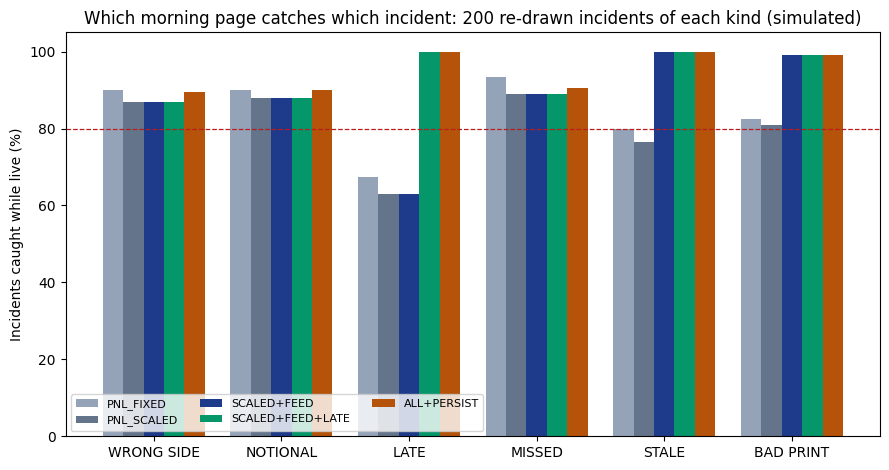

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(KINDS))
cols = ['#94a3b8', '#64748b', '#1e3a8a', '#059669', '#b45309']
for j, p in enumerate(POLICIES):
    ax.bar(x + (j - 2) * 0.16, 100 * t.loc[p, KINDS].astype(float), 0.16, color=cols[j], label=p)
ax.axhline(80, color='#b91c1c', lw=0.9, ls='--')
ax.set_xticks(x)
ax.set_xticklabels([k.replace('_', ' ') for k in KINDS])
ax.set_ylabel('Incidents caught while live (%)')
ax.set_ylim(0, 105)
ax.set_title('Which morning page catches which incident: 200 re-drawn incidents of each kind (simulated)')
ax.legend(fontsize=8, ncol=3, loc='lower left')
plt.tight_layout()
plt.show()


## 11 · Model controls and interpretation

**Reproducibility and arithmetic checks**

- A fixed random seed (`2024`) ensures reproducible simulated trials.
- The experiment compares the same injected incidents under all five candidate policies.
- The selection rule is set in code before evaluating the scorecard.
- All six family rates, clean-year alert totals and median detected-case delays are calculated explicitly.
- The JSON export independently checks trial counts, hit rates, false alerts and selected policy.

**Limitations**

1. The clean baseline and retrospective corrections are constructed with hindsight. This is an **offline benchmark**, not deployable contemporaneous ground truth.
2. Clean 2023 observations are used to estimate P&L noise; false-alert counts on those observations are **not out-of-sample performance**.
3. Synthetic incidents are injected one at a time from a specified simulation distribution; simultaneous errors, changing markets and operational dependencies are not covered.
4. `Median delay` is calculated among detected incidents; a low delay alone does not characterize missed incidents.
5. Meeting the exercise rule is not formal regulatory, trading-desk or model-risk approval.

**Control takeaway:** Combining scaled P&L, feed-quality and booking-timing checks covers failure modes that no single P&L screen handles reliably.


## 12 · Reporting handoff: Python → JSON → C# → Excel

Python owns the simulation, measurement and policy selection. The C#/.NET 10 exporter built with ClosedXML owns workbook creation and the user-facing analysis views. The Excel workbook is a **publication and review layer**; it does not rerun the 1,200 simulations or independently approve a policy.

| Workbook worksheet | Reviewer workflow |
|:--|:--|
| `01 Policy Overview` | Check final candidate and sign-off rationale |
| `02 Policy Scorecard` | Compare recall, clean alerts and eligibility |
| `03 Detection Matrix` | Investigate gaps by incident family |
| `04 Clean Timeline` | Trace false alerts to specific clean mornings |
| `05 Policy Drilldown` | Change policy / report-date selections |
| `06 DV01 Sensitivity` | Inspect detection versus booking-error risk size |
| `07 Trial Register` | Audit the 1,200 simulated trials |
| `08 Methodology` | Check rule definitions and limitations |

**Generated files** are placed under `Excel_Template_Output/` and excluded from Git, while the C# source remains version controlled under `Excel_Template_Design/`.


In [14]:
# TASK 5 | POLICY REVIEW / ALERT OPTIMIZATION -> C# EXCEL SNAPSHOT
# Run the original Task 5 computation first (through the policy table `t`).
# The incident-injection simulation and approval rule stay in Python.
# C# only publishes and audits the simulation results; it does NOT refit a policy.

import json
import os
from pathlib import Path
import numpy as np
import pandas as pd

needed = ['POLICIES', 'KINDS', 'RULE', 't', 'res', 'clean', 'sizes',
          'y23', 'y24', 'DATES', 'U_clean', 'g2', 's', 'FIXED', 'policy_flags']
missing = [name for name in needed if name not in globals()]
if missing:
    raise RuntimeError('Run the original Task 5 calculation first; missing: ' + ', '.join(missing))

# Locate project root, including when notebook is in Task5_Review_Policy/.
if os.environ.get('RAD_RISK_ROOT'):
    ROOT = Path(os.environ['RAD_RISK_ROOT']).expanduser().resolve()
else:
    current = Path.cwd().resolve()
    ROOT = next((p for p in (current, *current.parents)
                 if (p / 'DataSource' / 'rates_desk_feed.csv').is_file()), None)
    if ROOT is None:
        raise FileNotFoundError('Cannot find DataSource/rates_desk_feed.csv. Set RAD_RISK_ROOT.')

OUT = ROOT / 'Excel_Template_Output'
OUT.mkdir(parents=True, exist_ok=True)
policy_names = list(POLICIES)
kinds = list(KINDS)
incidents_per_kind = 200
assert len(policy_names) == 5 and len(kinds) == 6
assert all(len(res[name][kind]) == incidents_per_kind
           for name in policy_names for kind in kinds)

# Precommitted rule: >=90% overall, >=80% per kind, <=5 clean flags in EACH year.
# Tie-break: fewest combined clean flags, then shortest median delay.
passing = t[t['passes']]
selected = (passing.assign(total_clean=passing['clean23'] + passing['clean24'])
            .sort_values(['total_clean', 'delay']).index[0]
            if len(passing) else '')

policy_records = []
for name in policy_names:
    r = t.loc[name]
    per_kind = []
    for kind in kinds:
        hits = sum(bool(ok) for ok, delay in res[name][kind])
        assert np.isclose(hits / incidents_per_kind, float(r[kind]), atol=1e-10)
        per_kind.append({'kind': kind, 'rate': float(r[kind]), 'caught': int(hits)})
    policy_records.append({
        'name': name,
        'signals': list(POLICIES[name]),
        'overall': float(r['all']),
        'byKind': per_kind,
        'medianDelay': float(r['delay']),
        'clean2023': int(r['clean23']),
        'clean2024': int(r['clean24']),
        'passes': bool(r['passes'])
    })

# A 1,200-row trial register makes the policy scorecard auditable. Each trial has
# the same injected incident under all five candidate policies.
trials = []
for kind in kinds:
    for index in range(incidents_per_kind):
        trials.append({
            'trialId': f'{kind}-{index + 1:03d}',
            'kind': kind,
            'results': [{
                'policy': name,
                'caught': bool(res[name][kind][index][0]),
                'delay': (int(res[name][kind][index][1])
                          if res[name][kind][index][1] is not None else None)
            } for name in policy_names]
        })

# The CLEAN world is the corrected feed + corrected position book, NOT a live
# operational stream. This is useful for measuring false alarms with hindsight.
clean_days = []
for year, idx in [(2023, y23), (2024, y24)]:
    sig = clean[year]
    zvals = U_clean[idx] / (np.sqrt(2.0) * s * g2[idx])
    per_policy = {name: policy_flags(name, sig) for name in policy_names}
    for j, day_index in enumerate(idx):
        clean_days.append({
            'date': pd.Timestamp(DATES[day_index]).strftime('%Y-%m-%d'),
            'year': year,
            'unexplained': float(U_clean[day_index]),
            'zScore': float(zvals[j]),
            'signals': {key: bool(sig[key][j]) for key in
                        ['pnl_fixed', 'pnl_scaled', 'stale', 'kink', 'late', 'persist']},
            'policyFlags': {name: bool(per_policy[name][j]) for name in policy_names}
        })

# Booking-error DV01 sensitivity: exactly 600 injected WRONG_SIDE, NOTIONAL,
# MISSED incidents, scored against PNL_SCALED only.
size_df = pd.DataFrame(sizes, columns=['dv01', 'caught'])
size_df['band'] = pd.cut(size_df['dv01'],
                         [0, 2500, 10000, 40000, np.inf],
                         labels=['under 2.5k', '2.5k-10k', '10k-40k', 'over 40k'])
bands = []
for label, grp in size_df.groupby('band', observed=True):
    bands.append({'band': str(label), 'total': int(len(grp)),
                  'caught': int(grp['caught'].sum()),
                  'rate': float(grp['caught'].mean())})
assert len(size_df) == 600 and sum(b['total'] for b in bands) == 600

# Verify no rate, flag or delay was accidentally changed by the export.
assert len(clean_days) == len(y23) + len(y24) == 518
for rec in policy_records:
    for yr in (2023, 2024):
        n = sum(d['policyFlags'][rec['name']] for d in clean_days if d['year'] == yr)
        assert n == rec[f'clean{yr}']
    observed = sum(r['caught'] for r in rec['byKind']) / len(trials)
    assert np.isclose(observed, rec['overall'], atol=1e-10)

payload = {
    'asOf': pd.Timestamp(DATES[y24[-1]]).strftime('%Y-%m-%d'),
    'experiment': 'Simulated clean world + one synthetic incident per trial',
    'precommittedRule': RULE,
    'simulationSeed': 2024,
    'incidentsPerKind': incidents_per_kind,
    'noiseBp': float(s),
    'fixedThresholdUsd': float(FIXED),
    'winner': str(selected),
    'kindNames': kinds,
    'policyNames': policy_names,
    'policies': policy_records,
    'cleanDays': clean_days,
    'trialRecords': trials,
    'dv01Bands': bands
}

output = OUT / 'task5_snapshot.json'
output.write_text(json.dumps(payload, allow_nan=False, indent=2), encoding='utf-8')
print('Task 5 JSON:', output)
print('Policies:', len(policy_records), '| Synthetic trials:', len(trials),
      '| Clean days:', len(clean_days), '| Booking trials:', len(size_df))
print('Approved policy:', selected if selected else 'NONE')
print('Default 2023 / 2024 clean flags:',
      next((f"{p['clean2023']} / {p['clean2024']}" for p in policy_records
            if p['name'] == selected), 'N/A'))


Task 5 JSON: /mnt/data/Excel_Template_Output/task5_snapshot.json
Policies: 5 | Synthetic trials: 1200 | Clean days: 518 | Booking trials: 600
Approved policy: SCALED+FEED+LATE
Default 2023 / 2024 clean flags: 1 / 0


### 12.1 Generate the Excel workbook (optional local step)

On Windows with .NET 10 installed, the following cell invokes the standalone file `Excel_Template_Design/DeskRiskPolicy_Task5.cs`. It checks for the compiler before invoking it so **Python-only GitHub readers can run the notebook without a .NET installation**. No VBA is required.


In [15]:
import shutil
import subprocess

CS_FILE = PROJECT_ROOT / "Excel_Template_Design" / "DeskRiskPolicy_Task5.cs"
if not CS_FILE.is_file():
    print(f"Excel generator not found: {CS_FILE}. Skipping optional C# step.")
elif shutil.which("dotnet") is None:
    print(".NET SDK unavailable; skipping optional Excel workbook generation.")
else:
    result = subprocess.run(
        ["dotnet", "run", "--file", str(CS_FILE)],
        cwd=PROJECT_ROOT,
        capture_output=True,
        text=True,
        encoding="utf-8",
        errors="replace",
    )
    print("Exit Code:", result.returncode)
    print(result.stdout)
    print(result.stderr)
    if result.returncode != 0:
        raise RuntimeError("Task 5 C# Excel generation failed.")


Excel generator not found: /mnt/data/Excel_Template_Design/DeskRiskPolicy_Task5.cs. Skipping optional C# step.


## 13 · Conclusion and next step

The experiment selected **`SCALED+FEED+LATE`** because it met the overall and incident-family detection requirements while remaining below the false-alert ceiling in both clean years. The broader persistence-enhanced policy had higher overall detection, but failed the pre-specified clean-year constraint.

**Delivered:** a reproducible Python policy-evaluation experiment, a fully auditable 1,200-trial JSON export, and a C#-generated interactive Excel review workflow.

**Next step:** combine Tasks 1–5 into a consolidated front-office monitoring workbook with a unified daily risk snapshot, P&L explain, incident investigation, policy decision record and data lineage.

---

*Educational RiskHub-based fixed-income risk simulation. Metrics are simulated evaluation outcomes and should not be represented as production desk performance.*
